# 多层感知机（Multilayer Perceptron, MLP）

## 结构

多层感知机+非线性激活函数，可以构造出复杂分割面。

神经元可以看成“线性组合+激活函数”，如果激活函数是非线性的，就可以对非线性可分数据进行分类。

## 课堂练习

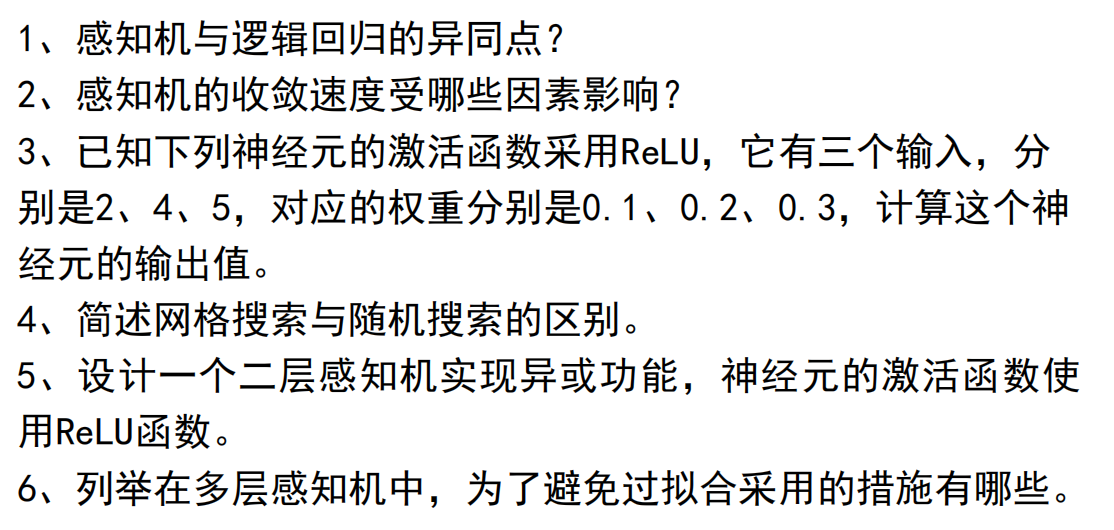

1. 相同：都是二分类线性模型，决策边界都是 $w^Tx+b=0$。不同：感知机直接输出类别并依据误分类更新；逻辑回归经 Sigmoid 输出概率，通常用交叉熵训练。
2. 初始参数、样本的排列/访问顺序、数据本身的分布及可分程度（尤其分类间隔）。学习率在实际训练里也会影响更新幅度，不过经典感知机收敛理论里，更核心的是数据是否线性可分以及间隔大小。
3. 2.5
4. 网格搜索枚举预先设定的参数组合；随机搜索随机抽取若干参数组合。在实验次数有限时，随机搜索通常能更充分地探索重要超参数。
5. 见下文
6. L1/L2 正则化、提前停止（Early Stopping）、Dropout、数据增强。

对，**“设计一个能实现 XOR 的网络”这类题不要求你训练**。你完全可以直接人工指定权重，只要四种输入都得到正确结果即可。

不过你现在这个方案有一个问题：**题目明确要求使用 ReLU，而你用了 0.5 阈值函数**。你描述的其实正是另一种 XOR 构造法，但不是这道题要求的 ReLU 版本。

你的思路稍微改一下就可以直接变成 ReLU：

$$
h_1=\operatorname{ReLU}(x_1-x_2)
$$

$$
h_2=\operatorname{ReLU}(-x_1+x_2)
$$

也就是两个隐藏神经元的权重分别：

$$
w_1=(1,-1),\qquad w_2=(-1,1)
$$

偏置都取 0。

四种输入看看：

$$
(0,0)\rightarrow(0,0)
$$

$$
(1,0)\rightarrow(1,0)
$$

$$
(0,1)\rightarrow(0,1)
$$

$$
(1,1)\rightarrow(0,0)
$$

输出层再取：

$$
\hat y=\operatorname{ReLU}(h_1+h_2)
$$

所以：

$$
(0,0)\to0,\quad
(1,0)\to1,\quad
(0,1)\to1,\quad
(1,1)\to0
$$

恰好就是 XOR。

所以你的核心想法其实非常好：**两个隐藏神经元分别检测“\(x_1>x_2\)”和“\(x_2>x_1\)”**。只需要把“阈值 0.5”改成 ReLU，就完全符合题目要求了。

而且这道题确实不是要考 BP，而是在考你是否理解：

$$
\text{隐藏层构造新特征}
\rightarrow
\text{使原本线性不可分的 XOR 可以表示}
$$

这比背 PPT 里某组特定权重更重要。
